### Bagian 0: Setup

In [1]:
# Sel 1: setup
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent))   # supaya "src" bisa di-import

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src import config as C
from src import audit as A
from src import viz as V

C.AUDIT_DIR.mkdir(parents=True, exist_ok=True)
C.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = C.AUDIT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def simpan(fig, nama):
    """Menyimpan gambar ke outputs/audit/figures/<nama>.png lalu menampilkannya sekali."""
    if fig is None:              # fungsi show_* mengembalikan None jika tidak ada data
        return
    path = FIG_DIR / f"{nama}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()                   # tampilkan di notebook
    plt.close(fig)               # bebaskan memori, mencegah gambar tampil dua kali
    print("Tersimpan:", path.name)

### Bagian 1: Audit dasar (seluruh 1.724 citra)

In [2]:
# Sel 2: jalankan audit
images_df, instances_df, issues_df = A.run_audit()
print(len(images_df), "citra |", len(instances_df), "instance |", len(issues_df), "masalah")
if len(issues_df):
    display(issues_df.groupby(["split", "issue"]).size().rename("jumlah"))

audit test: 100%|██████████| 267/267 [00:44<00:00,  5.97it/s]

1724 citra | 6576 instance | 0 masalah


In [3]:
# Sel 3: Analisis A, B, C
display(A.compare_official(images_df, instances_df))
display(A.size_summary(images_df))
display(A.empty_label_summary(images_df))

,split,item,observed,official,match
0,train,citra,1281,1281,True
1,train,Scab,3188,3188,True
2,train,Rot,903,903,True
3,train,Greening,79,79,True
4,train,Mechanical Damage,562,562,True
5,val,citra,176,176,True
6,val,Scab,548,548,True
7,val,Rot,175,175,True
8,val,Greening,17,17,True
9,val,Mechanical Damage,108,108,True


split                test        train          val
h      count   267.000000  1281.000000   176.000000
       mean   1628.853933  1663.862607  1687.488636
       std     476.288017   497.527713   506.134392
       min     732.000000   763.000000   758.000000
       25%    1272.000000  1275.000000  1297.500000
       50%    1524.000000  1544.000000  1566.500000
       75%    2005.500000  2071.000000  2050.000000
       max    2724.000000  2933.000000  2851.000000
w      count   267.000000  1281.000000   176.000000
       mean   1793.629213  1788.544887  1773.465909
       std     512.201530   501.906177   527.564440
       min     825.000000   707.000000   745.000000
       25%    1370.000000  1384.000000  1348.750000
       50%    1725.000000  1755.000000  1712.500000
       75%    2275.500000  2217.000000  2237.250000
       max    2814.000000  2877.000000  2967.000000
aspect count   267.000000  1281.000000   176.000000
       mean      1.219213     1.200495     1.176312
       std       0.506870     0.515116     0.525297
       min       0.417669     0.411631     0.444444
       25%       0.676951     0.650146     0.649106
       50%       1.394113     1.364139     1.345552
       75%       1.645824     1.631434     1.646079
       max       2.089765     2.365639     2.234359

split
test      9
train    80
val       5
Name: citra_tanpa_instance, dtype: int64

In [4]:
# Sel 4: Analisis D - instance raksasa
display(A.coverage_summary(instances_df))
display(A.giant_images_summary(instances_df))

,count,mean,std,min,50%,90%,99%,max,n_cov>=0.5,n_cov>=0.9,n_sentuh_4_tepi
class_name,,,,,,,,,,,
Greening,125.0,0.140890,0.153743,0.004923,0.087548,0.373891,0.653916,0.705501,8,0,0
Mechanical Damage,793.0,0.009911,0.019128,0.000470,0.004539,0.019556,0.089625,0.223290,0,0,0
Rot,1268.0,0.017421,0.035751,0.000112,0.004689,0.046801,0.184451,0.391789,0,0,0
Scab,4390.0,0.163102,0.323807,0.000032,0.001943,0.859334,0.987628,0.993362,750,362,258


,split,class_name,jumlah_citra
0,test,Scab,54
1,train,Scab,266
2,val,Scab,37


In [5]:
# Sel 5: Analisis E - overlap, dua versi
print("Semua instance:")
display(A.overlap_summary(images_df, "all"))
print("Tanpa instance raksasa:")
display(A.overlap_summary(images_df, "nogiant"))

Semua instance:


,pasangan,jumlah_citra,total_piksel
0,Scab & Rot,277,11981881
1,Scab & Greening,43,4809406
2,Scab & Mechanical Damage,188,4430535
3,Rot & Greening,9,89239
4,Rot & Mechanical Damage,39,1595537
5,Greening & Mechanical Damage,11,101098


Tanpa instance raksasa:


,pasangan,jumlah_citra,total_piksel
0,Scab & Rot,162,4738984
1,Scab & Greening,36,3369926
2,Scab & Mechanical Damage,96,1962276
3,Rot & Greening,9,89239
4,Rot & Mechanical Damage,39,1595537
5,Greening & Mechanical Damage,11,101098


In [6]:
# Sel 6: Analisis F dan G - risiko kebocoran
display(A.split_adjacency(images_df))
dup_df = A.near_duplicates(images_df)
print("Total kandidat hampir identik lintas split:", len(dup_df))

{'pasangan_berurutan': 1706,
 'proporsi_beda_split_teramati': 0.41207502930832357,
 'proporsi_harapan_jika_acak': 0.4134849349432874,
 'jumlah_celah_nomor': 17,
 'nomor_duplikat': 0}

pHash: 100%|██████████| 1724/1724 [01:09<00:00, 24.87it/s]


Total kandidat hampir identik lintas split: 21


In [7]:
# Sel 7: simpan hasil audit dasar
images_df.to_csv(C.AUDIT_DIR / "images.csv", index=False)
instances_df.to_csv(C.AUDIT_DIR / "instances.csv", index=False)
issues_df.to_csv(C.AUDIT_DIR / "issues.csv", index=False)
dup_df.to_csv(C.AUDIT_DIR / "near_duplicates.csv", index=False)

### Bagian 2: Penghapusan citra tanpa anotasi

In [8]:
# Sel 8: manifest
manifest = A.build_manifest(images_df)
manifest.to_csv(C.MANIFEST_PATH, index=False)
display(A.split_counts(manifest))

kept = A.kept_images(images_df, manifest)
keep_set = set(zip(kept["split"], kept["file"]))
print("Citra dipakai:", len(kept))

,sebelum,dipakai,dihapus
split,,,
train,1281,1201,80
val,176,171,5
test,267,258,9


Citra dipakai: 1630


### Bagian 3: Audit lanjutan (hanya citra yang dipakai)

In [9]:
# Sel 9: AUDIT 4 - jumlah citra dan instance per kelas per split
per_class = A.images_per_class(kept)
print("Jumlah citra:")
display(per_class.pivot(index="kelas", columns="split", values="jumlah_citra")[list(C.SPLITS)])
print("Jumlah instance:")
display(per_class.pivot(index="kelas", columns="split", values="jumlah_instance")[list(C.SPLITS)])

Jumlah citra:


split,train,val,test
kelas,,,
Greening,68,15,25
Mechanical Damage,375,65,72
Rot,475,80,108
Scab,1088,158,238


Jumlah instance:


split,train,val,test
kelas,,,
Greening,79,17,29
Mechanical Damage,562,108,123
Rot,903,175,190
Scab,3188,548,654


In [10]:
# Sel 10: AUDIT 3 - ukuran lesi setelah resize
lesion = A.lesion_size_after_resize(instances_df, kept)
print(f"Persentase lesi < {C.TINY_LESION_PX} piksel:")
display(lesion.pivot(index="kelas", columns="resolusi", values=f"persen_<{C.TINY_LESION_PX}px"))
print("Median luas lesi (piksel):")
display(lesion.pivot(index="kelas", columns="resolusi", values="median_px"))

Persentase lesi < 16 piksel:


resolusi,512,768,1024
kelas,,,
Greening,0.0,0.0,0.0
Mechanical Damage,0.0,0.0,0.0
Rot,0.1,0.0,0.0
Scab,1.2,0.1,0.0


Median luas lesi (piksel):


resolusi,512,768,1024
kelas,,,
Greening,11329.6,25491.7,45318.5
Mechanical Damage,578.8,1302.3,2315.2
Rot,613.0,1379.3,2452.1
Scab,253.5,570.3,1013.9


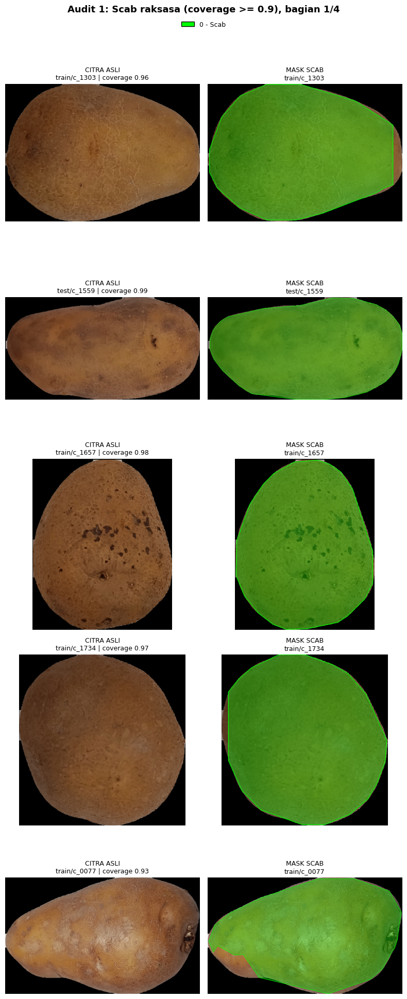

Tersimpan: audit1_scab_raksasa_bagian1.png


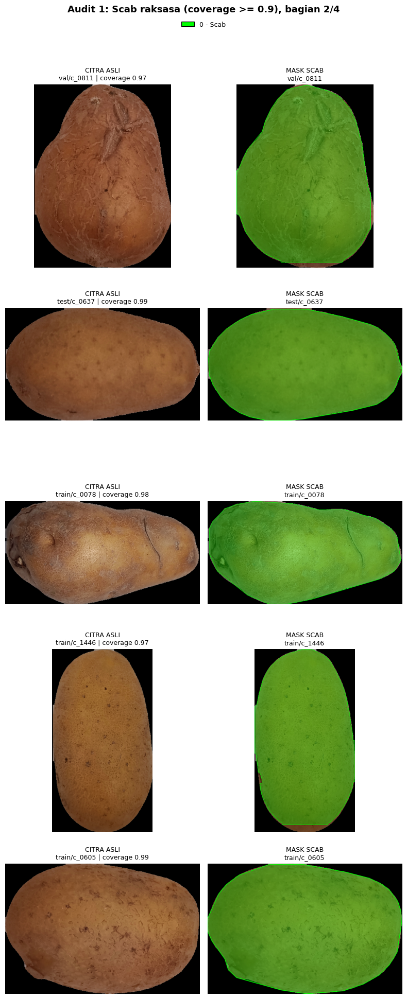

Tersimpan: audit1_scab_raksasa_bagian2.png


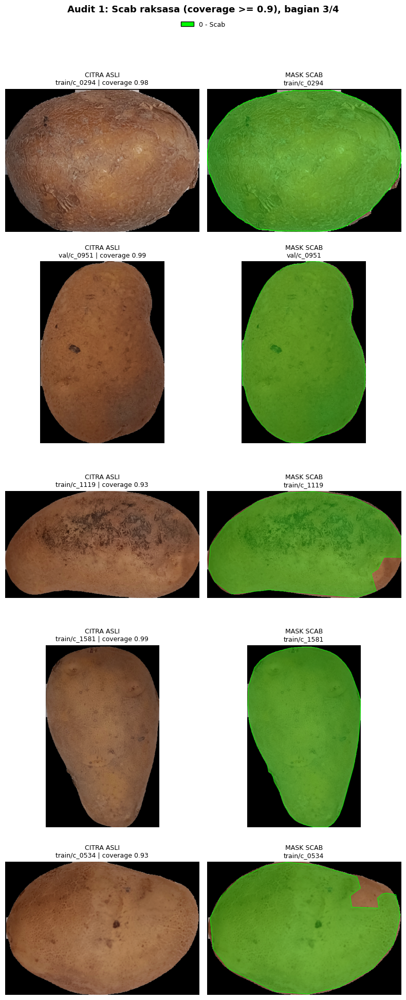

Tersimpan: audit1_scab_raksasa_bagian3.png


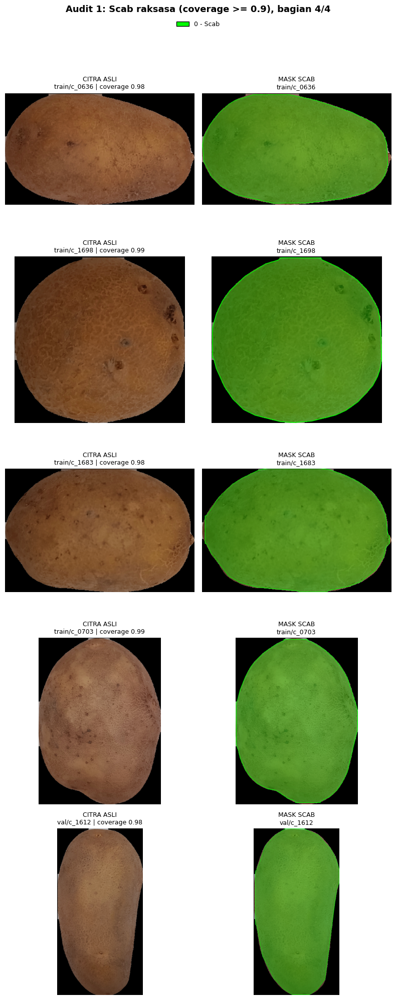

Tersimpan: audit1_scab_raksasa_bagian4.png


In [11]:
# Sel 11: AUDIT 1 - Scab raksasa, citra asli vs mask Scab (20 sampel, per 5 baris)
giant = (instances_df[instances_df["is_giant"]]
         .groupby(["split", "file"], as_index=False)["coverage"].max()
         .sample(n=20, random_state=C.SEED))
giant_items = [(r.split, r.file, f"coverage {r.coverage:.2f}") for r in giant.itertuples()]

for i in range(0, len(giant_items), 5):
    bagian = i // 5 + 1
    fig = V.show_side_by_side(
        giant_items[i:i + 5],
        title=f"Audit 1: Scab raksasa (coverage >= {C.GIANT_COVERAGE}), bagian {bagian}/4",
        class_id=0,
    )
    simpan(fig, f"audit1_scab_raksasa_bagian{bagian}")

In [ ]:
# Sel 12: AUDIT 2 - ringkasan pasangan hampir identik (citra yang dipakai saja)
dup_kept = dup_df[[((r.split_a, r.file_a) in keep_set) and ((r.split_b, r.file_b) in keep_set)
                   for r in dup_df.itertuples()]]
print("Total kandidat (semua citra)   :", len(dup_df))
print("Total kandidat (citra dipakai) :", len(dup_kept))
display(dup_kept["distance"].value_counts().sort_index().rename("jumlah_pasangan"))
display(dup_kept.groupby(["split_a", "split_b"]).size().rename("jumlah_pasangan"))

Total kandidat (semua citra)   : 21
Total kandidat (citra dipakai) : 19


distance
0     1
2     4
4    14
Name: jumlah_pasangan, dtype: int64

split_a  split_b
train    test       10
         val         8
val      test        1
Name: jumlah_pasangan, dtype: int64

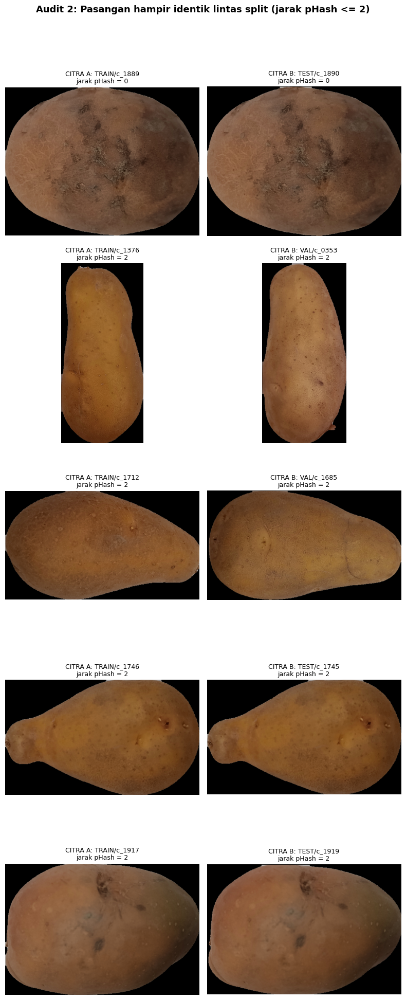

Tersimpan: audit2_duplikat_jarak_le2.png


In [13]:
# Sel 13: AUDIT 2 - visual pasangan dengan jarak <= 2
close_pairs = dup_kept[dup_kept["distance"] <= 2].sort_values("distance")
fig = V.show_pairs(close_pairs,
                   title="Audit 2: Pasangan hampir identik lintas split (jarak pHash <= 2)")
simpan(fig, "audit2_duplikat_jarak_le2")

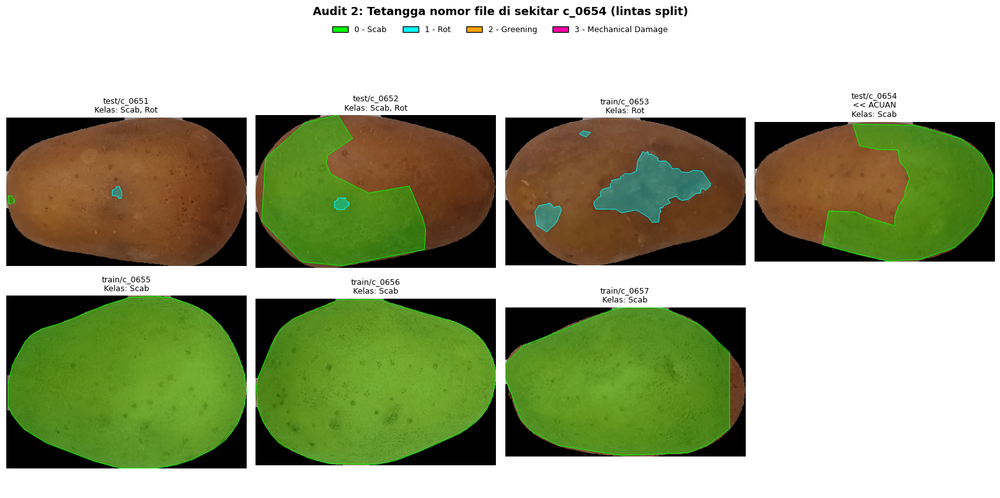

Tersimpan: audit2_tetangga_c_0654.png


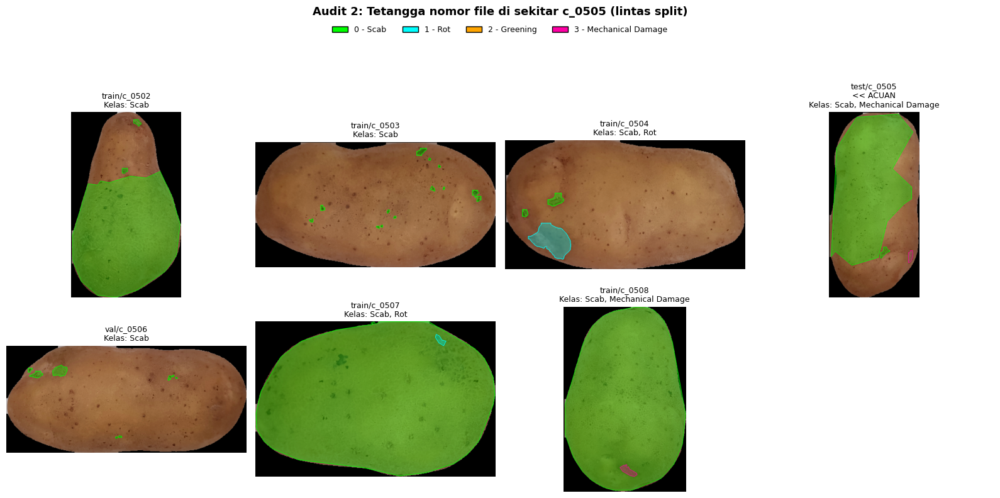

Tersimpan: audit2_tetangga_c_0505.png


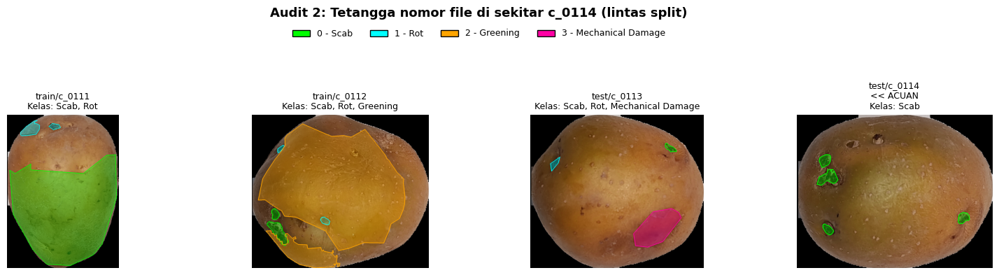

Tersimpan: audit2_tetangga_c_0114.png


In [14]:
# Sel 14: AUDIT 2 - tetangga nomor file untuk 3 citra test
test_stems = kept[kept["split"] == "test"].sample(3, random_state=C.SEED)["file"]
for stem in test_stems:
    fig = V.show_grid(V.neighbor_items(images_df, stem),
                      title=f"Audit 2: Tetangga nomor file di sekitar {stem} (lintas split)",
                      ncols=4, size=4)
    simpan(fig, f"audit2_tetangga_{stem}")

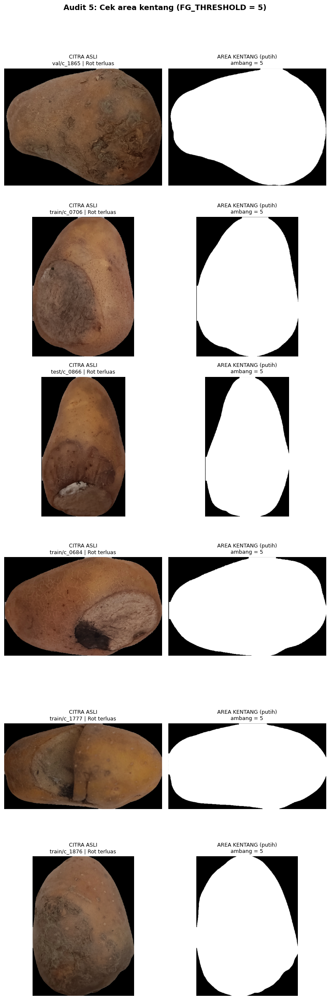

Tersimpan: audit5_area_kentang_rot.png


In [15]:
# Sel 15: AUDIT 5 - mask area kentang pada citra dengan Rot terluas
rot_top = (instances_df[instances_df["class_id"] == 1]
           .groupby(["split", "file"], as_index=False)["area_px"].sum()
           .nlargest(6, "area_px"))
fig = V.show_foreground([(r.split, r.file, "Rot terluas") for r in rot_top.itertuples()],
                        title=f"Audit 5: Cek area kentang (FG_THRESHOLD = {C.FG_THRESHOLD})")
simpan(fig, "audit5_area_kentang_rot")

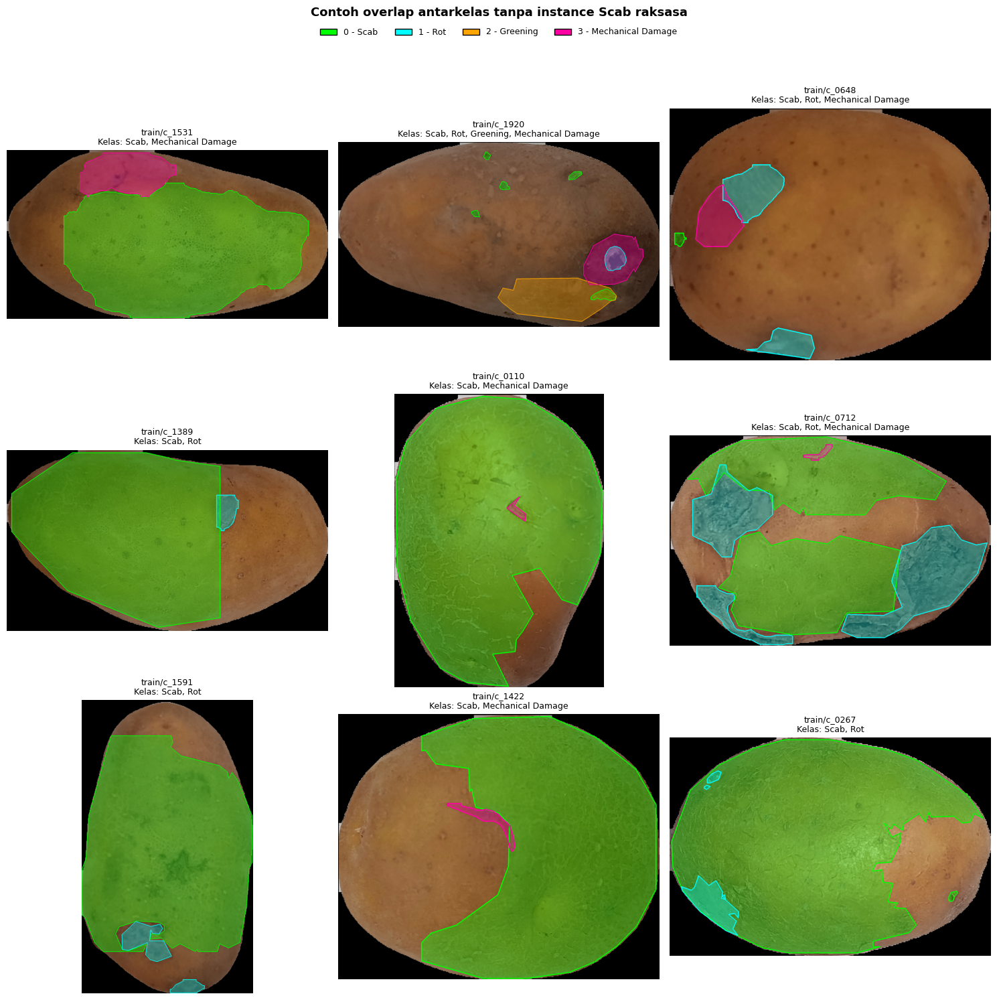

Tersimpan: audit_overlap_tanpa_raksasa.png


In [16]:
# Sel 16: contoh overlap yang tidak melibatkan instance raksasa (citra dipakai)
ov_cols = [c for c in kept.columns if c.endswith("_nogiant")]
ov_files = kept[kept[ov_cols].sum(axis=1) > 0]
sample = ov_files.sample(n=min(9, len(ov_files)), random_state=C.SEED)
fig = V.show_grid([(r.split, r.file, "") for r in sample.itertuples()],
                  title="Contoh overlap antarkelas tanpa instance Scab raksasa")
simpan(fig, "audit_overlap_tanpa_raksasa")

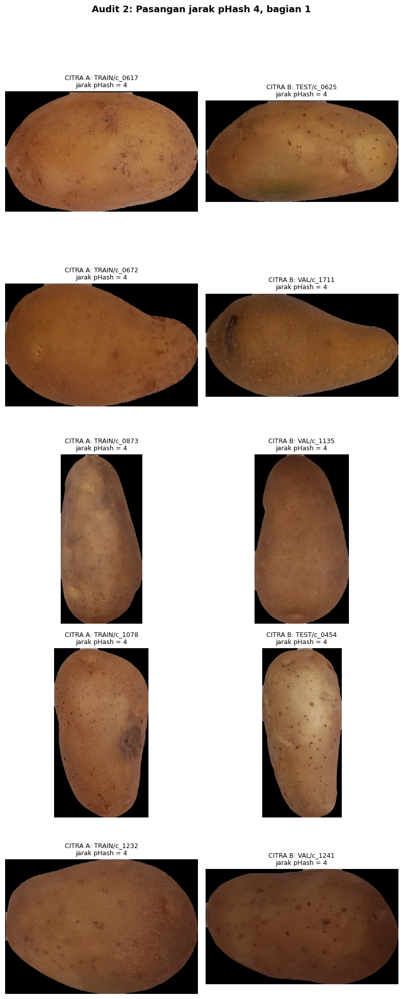

Tersimpan: audit2_duplikat_jarak4_bagian1.png


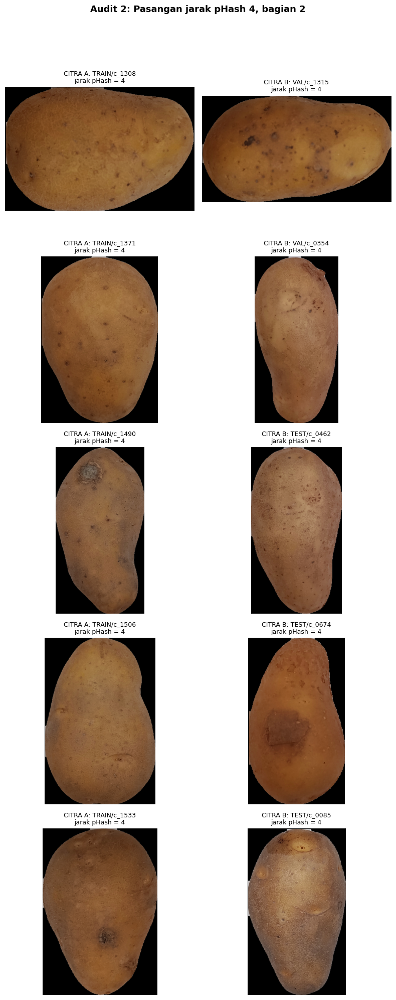

Tersimpan: audit2_duplikat_jarak4_bagian2.png


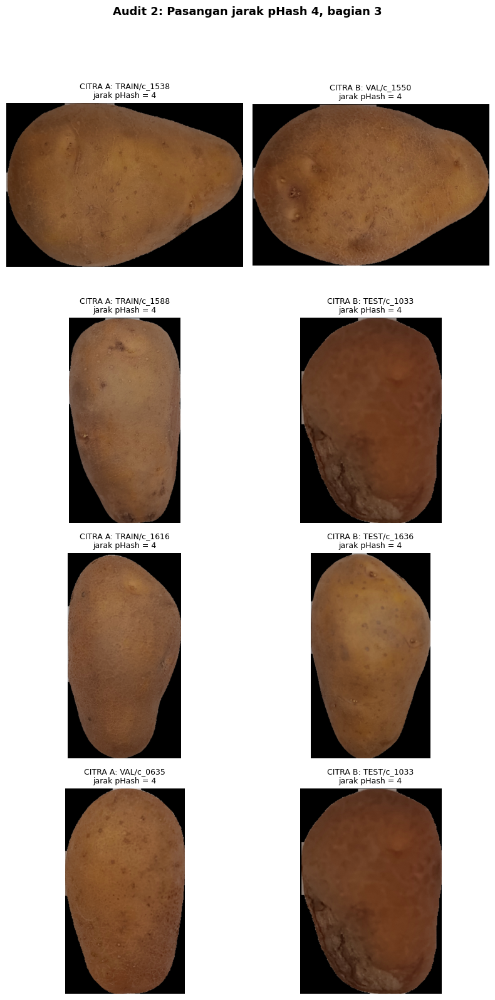

Tersimpan: audit2_duplikat_jarak4_bagian3.png
Isi penilaian di: D:\Arsip Hafizh Fadhl Muhammad\Project\skripsi\segmentasi-kentang\outputs\audit\review_duplikat.csv


In [17]:
# Sel 17: AUDIT 2 - visual pasangan jarak pHash 4 dan lembar review duplikat
far_pairs = dup_kept[dup_kept["distance"] == 4].reset_index(drop=True)
for i in range(0, len(far_pairs), 5):
    bagian = i // 5 + 1
    fig = V.show_pairs(far_pairs.iloc[i:i + 5],
                       title=f"Audit 2: Pasangan jarak pHash 4, bagian {bagian}")
    simpan(fig, f"audit2_duplikat_jarak4_bagian{bagian}")

review_path = C.AUDIT_DIR / "review_duplikat.csv"
if not review_path.exists():            # jangan menimpa hasil review yang sudah diisi
    pairs_review = dup_kept.sort_values("distance").copy()
    pairs_review["penilaian"] = ""      # isi: foto_sama / umbi_berbeda / ragu
    pairs_review.to_csv(review_path, index=False)
print("Isi penilaian di:", review_path)

In [20]:
# Sel 18: perbarui manifest dengan duplikat terkonfirmasi (jalankan SETELAH review diisi)
review_df = pd.read_csv(C.AUDIT_DIR / "review_duplikat.csv")
belum = review_df["penilaian"].isna().sum()
assert belum == 0, f"Masih ada {belum} pasangan belum dinilai"
display(review_df["penilaian"].value_counts())

manifest = A.apply_duplicates(manifest, review_df)
manifest.to_csv(C.MANIFEST_PATH, index=False)
display(manifest[manifest["is_duplicate"]])
display(A.split_counts(manifest))

penilaian
umbi_berbeda    16
foto_sama        3
Name: count, dtype: int64

,split,file,keep,reason,is_duplicate
1141,train,c_1746,False,duplikat_lintas_split,True
1247,train,c_1889,False,duplikat_lintas_split,True
1265,train,c_1917,False,duplikat_lintas_split,True


,sebelum,dipakai,dihapus
split,,,
train,1281,1198,83
val,176,171,5
test,267,258,9


In [21]:
# Sel 20: ringkasan akhir Modul 1
final = manifest[manifest["keep"]]
summary = {
    "citra_awal": len(images_df),
    "instance_awal": len(instances_df),
    "masalah_label": len(issues_df),
    "dihapus_tanpa_anotasi": int((manifest["reason"] == "tanpa_anotasi").sum()),
    "dihapus_duplikat": int(manifest["is_duplicate"].sum()),
    "dipakai_train": int((final["split"] == "train").sum()),
    "dipakai_val": int((final["split"] == "val").sum()),
    "dipakai_test": int((final["split"] == "test").sum()),
    "citra_dengan_scab_raksasa": int(instances_df.loc[instances_df["is_giant"], "file"].nunique()),
}
display(pd.Series(summary, name="nilai"))
pd.Series(summary).to_csv(C.AUDIT_DIR / "ringkasan_modul1.csv", header=["nilai"])

citra_awal                   1724
instance_awal                6576
masalah_label                   0
dihapus_tanpa_anotasi          94
dihapus_duplikat                3
dipakai_train                1198
dipakai_val                   171
dipakai_test                  258
citra_dengan_scab_raksasa     357
Name: nilai, dtype: int64